In [1]:
import re
import string

import requests

import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

import pandas as pd
import numpy as np

from transformers import BertTokenizer, GPT2Model, BertModel, GPT2Tokenizer

# GloVe
import gensim.downloader as api

# pytorch
import torch
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.nn.functional as F

from torchinfo import summary

import time

torch.manual_seed(42)

In [ ]:
# use this utility to preprocess the text (sentence); returns the cleaned text as a single string

def preprocess(text, min_len=2):
    strings2replace = [ '\r\n\r\nâ\x80\x9c','â\x80\x9c','â\x80\x9d','\r\n','â\x80\x94','â\x80\x99','â\x80\x98','_']
    for s in strings2replace:
        regexp = re.compile(s)
        text = regexp.sub(" ", text)

    text = re.sub(r'[^\x00-\x7F]+', ' ', text) # non ASCII characters
    text = re.sub(r'\d+','',text).lower() # digits
    
    words = re.split(fr'[{string.punctuation}\s]+',text)
    words = [item.strip() for item in words if item.strip()]
    words = [item for item in words if len(item) >= min_len]

    return " ".join(words)

In [2]:
text = "The flow of ink is smooth."
preprocess(text)

'the flow of ink is smooth'

# Embedding Vectors

## GloVe

### intro

In [3]:
glove = api.load("glove-wiki-gigaword-50") # glove dataset

In [4]:
print(dir(glove))

['__class__', '__contains__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getitem__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__len__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__setitem__', '__sizeof__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__', '_adapt_by_suffix', '_load_specials', '_log_evaluate_word_analogies', '_save_specials', '_smart_save', '_upconvert_old_d2vkv', '_upconvert_old_vocab', 'add_lifecycle_event', 'add_vector', 'add_vectors', 'allocate_vecattrs', 'closer_than', 'cosine_similarities', 'distance', 'distances', 'doesnt_match', 'evaluate_word_analogies', 'evaluate_word_pairs', 'expandos', 'fill_norms', 'get_index', 'get_mean_vector', 'get_normed_vectors', 'get_vecattr', 'get_vector', 'has_index_for', 'index2entity', 'index2word', 'index_to_key', 'init_sims', 

In [5]:
# total number of items
len(glove.key_to_index.keys()) # list of words for which the embeddings vectors are being calculated; not a tokenizer

400000

In [6]:
# random 10 words

np.random.choice(list(glove.key_to_index.keys()), size=10)

array(['xinshi', 'kemball', 'ropczyce-sędziszów', 'słubice', '1.585',
       'sackatoga', 'inwagen', 'post-doctoral', 'unmounted', '113.10'],
      dtype='<U68')

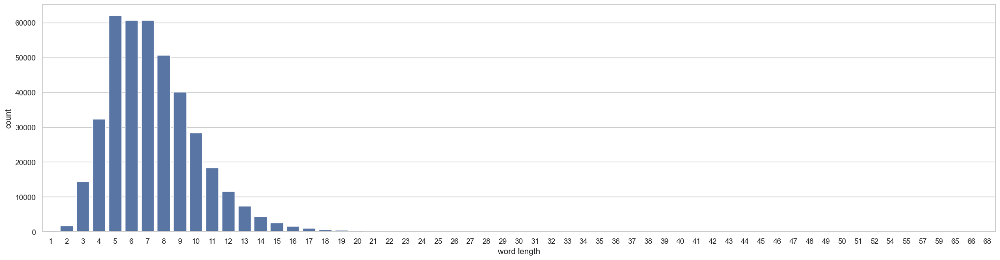

In [7]:
# distribution of token character length

lengths = [len(k) for k in  glove.key_to_index.keys()]
uniques, counts = np.unique(lengths, return_counts=True)

plt.figure(figsize=(25, 6))
sns.barplot(x=uniques, y=counts)
plt.xlabel("word length")
plt.ylabel("count");

In [8]:
# get index of a certain word

word = "apple"
print(glove.key_to_index[word])
print()
print(glove.get_index(word))

3292

3292


In [9]:
# exploring individual words

word = "banana"

idx = glove.key_to_index[word]
glove.vectors[idx, :]

array([-0.25522 , -0.75249 , -0.86655 ,  1.1197  ,  0.12887 ,  1.0121  ,
       -0.57249 , -0.36224 ,  0.44341 , -0.12211 ,  0.073524,  0.21387 ,
        0.96744 , -0.068611,  0.51452 , -0.053425, -0.21966 ,  0.23012 ,
        1.043   , -0.77016 , -0.16753 , -1.0952  ,  0.24837 ,  0.20019 ,
       -0.40866 , -0.48037 ,  0.10674 ,  0.5316  ,  1.111   , -0.19322 ,
        1.4768  , -0.51783 , -0.79569 ,  1.7971  , -0.33392 , -0.14545 ,
       -1.5454  ,  0.0135  ,  0.10684 , -0.30722 , -0.54572 ,  0.38938 ,
        0.24659 , -0.85166 ,  0.54966 ,  0.82679 , -0.68081 , -0.77864 ,
       -0.028242, -0.82872 ], dtype=float32)

In [10]:
# easier

word = "banana"
glove[word]

array([-0.25522 , -0.75249 , -0.86655 ,  1.1197  ,  0.12887 ,  1.0121  ,
       -0.57249 , -0.36224 ,  0.44341 , -0.12211 ,  0.073524,  0.21387 ,
        0.96744 , -0.068611,  0.51452 , -0.053425, -0.21966 ,  0.23012 ,
        1.043   , -0.77016 , -0.16753 , -1.0952  ,  0.24837 ,  0.20019 ,
       -0.40866 , -0.48037 ,  0.10674 ,  0.5316  ,  1.111   , -0.19322 ,
        1.4768  , -0.51783 , -0.79569 ,  1.7971  , -0.33392 , -0.14545 ,
       -1.5454  ,  0.0135  ,  0.10684 , -0.30722 , -0.54572 ,  0.38938 ,
        0.24659 , -0.85166 ,  0.54966 ,  0.82679 , -0.68081 , -0.77864 ,
       -0.028242, -0.82872 ], dtype=float32)

### Embedding matrix

In [11]:
glove.vectors # embedding vector

array([[ 0.418   ,  0.24968 , -0.41242 , ..., -0.18411 , -0.11514 ,
        -0.78581 ],
       [ 0.013441,  0.23682 , -0.16899 , ..., -0.56657 ,  0.044691,
         0.30392 ],
       [ 0.15164 ,  0.30177 , -0.16763 , ..., -0.35652 ,  0.016413,
         0.10216 ],
       ...,
       [-0.51181 ,  0.058706,  1.0913  , ..., -0.25003 , -1.125   ,
         1.5863  ],
       [-0.75898 , -0.47426 ,  0.4737  , ...,  0.78954 , -0.014116,
         0.6448  ],
       [ 0.072617, -0.51393 ,  0.4728  , ..., -0.18907 , -0.59021 ,
         0.55559 ]], shape=(400000, 50), dtype=float32)

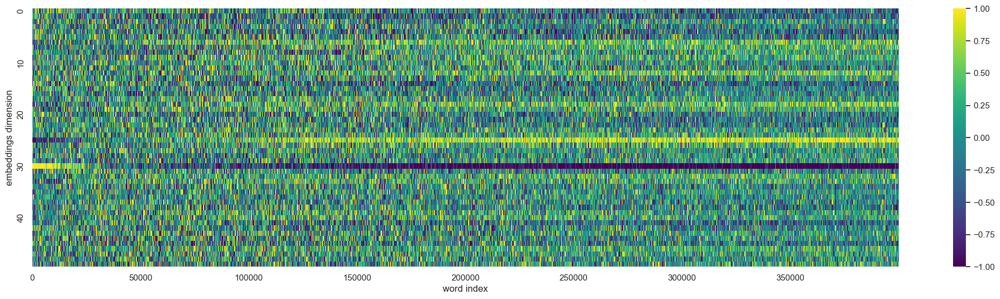

In [12]:
plt.figure(figsize=(25, 6))
sns.heatmap(glove.vectors.T, xticklabels=50000, yticklabels=10, vmin=-1, vmax=1, cmap="viridis")
plt.xlabel("word index")
plt.ylabel("embeddings dimension");

In [13]:
# mean and std across a single vector

random_idx = np.random.choice(glove.vectors.shape[0])
print(random_idx)
glove.vectors[random_idx, :].mean(), glove.vectors[random_idx, :].std()

320019


(np.float32(0.0023011537), np.float32(0.6237446))

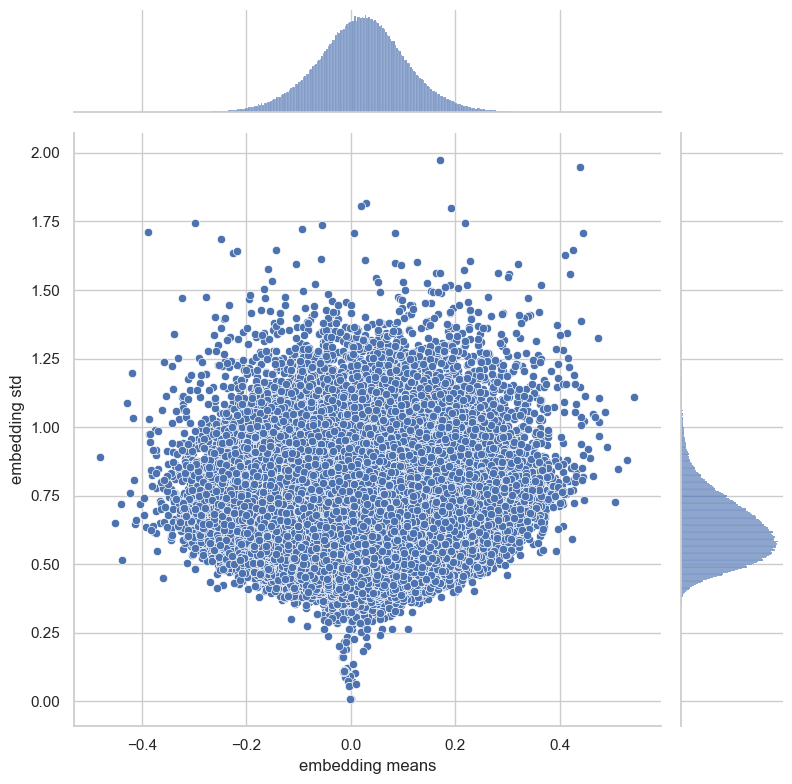

In [14]:
embedding_means = glove.vectors.mean(axis=1)
embedding_std = glove.vectors.std(axis=1)
data={"embedding means": embedding_means, "embedding std": embedding_std}
df_ = pd.DataFrame(data)
sns.jointplot(data=df_, x="embedding means", y="embedding std", height=8)

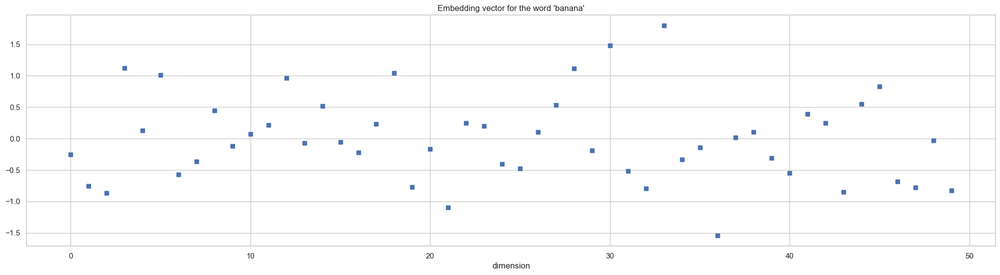

In [15]:
# embedding vector for a word

word = "banana"
vec_dim = glove.vectors.shape[1]
plt.figure(figsize=(25, 6))
plt.plot(range(vec_dim), glove[word], 's') # plotting coordinates of the embedding space
plt.title(f"Embedding vector for the word '{word}'")
plt.xlabel("dimension");

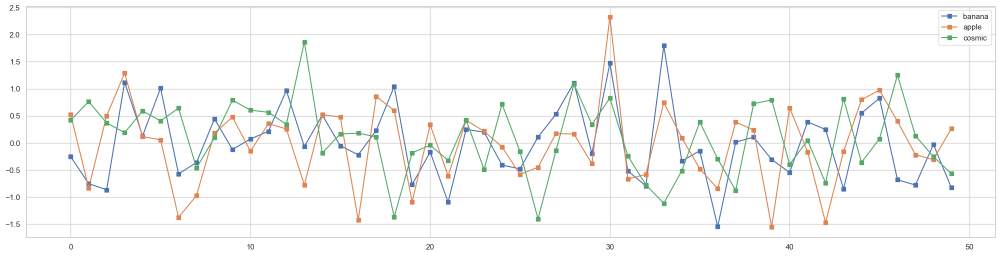

In [16]:
words = ["banana", "apple", "cosmic"]
vec_dim = glove.vectors.shape[1]

plt.figure(figsize=(25, 6))
for word in words:
    plt.plot(range(vec_dim), glove[word], "-s", label=word)
plt.legend();

In [17]:
print(glove.similarity("banana", "apple"))
print(glove.similarity("banana", "cosmic"))

0.56079274
-0.062682346


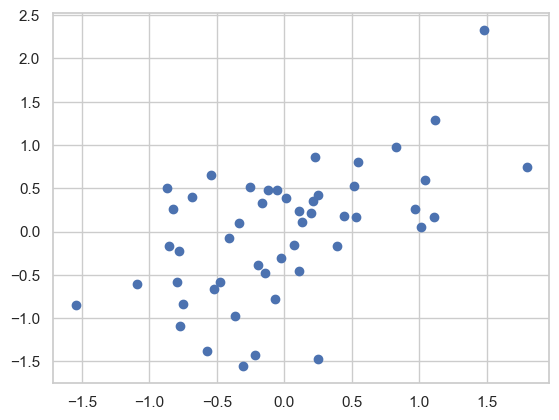

In [18]:
plt.plot(glove["banana"], glove["apple"], "o")

### more methods

In [19]:
glove.most_similar(["mountain"], topn=2)

[('mountains', 0.8784229755401611), ('valley', 0.8214774131774902)]

In [20]:
words = ['dog', 'ocean', 'guitar', 'mountain', 'coffee']

glove.doesnt_match(words)

'guitar'

In [21]:
glove.most_similar(words)[0]

('hot', 0.7921963334083557)

### Wikipedia versus Twitter embeddings

In [22]:
# download and inspect the models

wiki = api.load('glove-wiki-gigaword-50')
twit = api.load('glove-twitter-50')

In [23]:
print(dir(wiki))
print()
print(dir(twit))

['__class__', '__contains__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getitem__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__len__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__setitem__', '__sizeof__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__', '_adapt_by_suffix', '_load_specials', '_log_evaluate_word_analogies', '_save_specials', '_smart_save', '_upconvert_old_d2vkv', '_upconvert_old_vocab', 'add_lifecycle_event', 'add_vector', 'add_vectors', 'allocate_vecattrs', 'closer_than', 'cosine_similarities', 'distance', 'distances', 'doesnt_match', 'evaluate_word_analogies', 'evaluate_word_pairs', 'expandos', 'fill_norms', 'get_index', 'get_mean_vector', 'get_normed_vectors', 'get_vecattr', 'get_vector', 'has_index_for', 'index2entity', 'index2word', 'index_to_key', 'init_sims', 

In [24]:
print(wiki.vectors.shape)
print(twit.vectors.shape)

(400000, 50)
(1193514, 50)


0.102

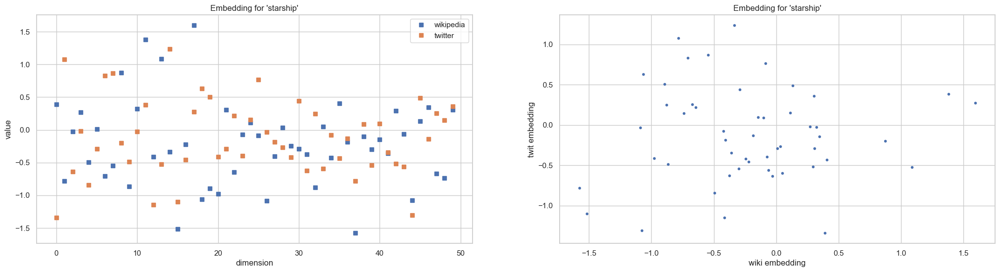

In [516]:
# embedding word for one word

cosine_similarity = lambda v1, v2: round(float(np.dot(np.ravel(v1), np.ravel(v2)) / (np.linalg.norm(v1) * np.linalg.norm(v2))), 3)

word = "starship"
embeding_vector_wiki = wiki.get_vector(word)
embeding_vector_twit = twit.get_vector(word)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(25, 6))
ax[0].plot(embeding_vector_wiki, "s", label="wikipedia")
ax[0].plot(embeding_vector_twit, "s", label="twitter")
ax[0].set_xlabel("dimension")
ax[0].set_ylabel("value")
ax[0].legend()
ax[0].set_title(f"Embedding for '{word}'")

ax[1].plot(embeding_vector_wiki, embeding_vector_twit, ".")
ax[1].set_xlabel("wiki embedding")
ax[1].set_ylabel("twit embedding")
ax[1].set_title(f"Embedding for '{word}'");

cosine_similarity(embeding_vector_wiki, embeding_vector_twit)

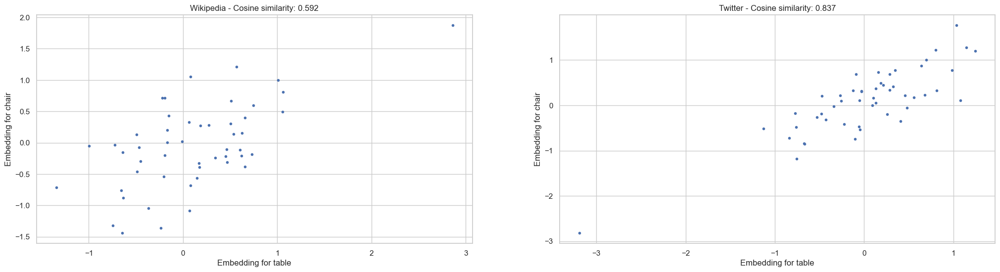

In [26]:
# embedding for word pairs within each model

word1, word2 = "table", "chair"

embedding_vector_wiki_word1 = wiki.get_vector(word1)
embedding_vector_wiki_word2 = wiki.get_vector(word2)
embedding_vector_twit_word1 = twit.get_vector(word1)
embedding_vector_twit_word2 = twit.get_vector(word2)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(25, 6))
ax[0].plot(embedding_vector_wiki_word1, embedding_vector_wiki_word2, ".")
ax[0].set_xlabel(f"Embedding for {word1}")
ax[0].set_ylabel(f"Embedding for {word2}")
ax[0].set_title(f"Wikipedia - Cosine similarity: {cosine_similarity(embedding_vector_wiki_word1, embedding_vector_wiki_word2)}");

ax[1].plot(embedding_vector_twit_word1, embedding_vector_twit_word2, ".")
ax[1].set_xlabel(f"Embedding for {word1}")
ax[1].set_ylabel(f"Embedding for {word2}")
ax[1].set_title(f"Twitter - Cosine similarity: {cosine_similarity(embedding_vector_twit_word1, embedding_vector_twit_word2)}");

In [27]:
cosine_similarity(embedding_vector_wiki_word1, embedding_vector_wiki_word2)

In [ ]:
# similar words within each models
word = "battery"

print(wiki.most_similar(word))
print()
print(twit.most_similar(word))

In [ ]:
# foxes and dogs
text = "the quick brown fox jumps over the lazy dog"

res = {"word": [word for word in text.split()], "wiki index": [wiki.get_index(word) for word in text.split()], "twit index": [twit.get_index(word) for word in text.split()]}
pd.DataFrame(res)

In [ ]:
# inter-word similarity

words = text.split()
inter_words = [f"{words[i]}-{words[i+1]}" for i in range(len(words)-1)]

x, y = [], []
for inter_word in inter_words:
    word1, word2 = inter_word.split("-")
    x.append(wiki.similarity(word1, word2))
    y.append(twit.similarity(word1, word2))

plt.figure(figsize=(10, 10))
plt.plot(x, y, ".")
_ = np.linspace(0, 1)
plt.plot(_, _, "-.")
for xi, yi, label in zip(x, y, inter_words):
    plt.text(xi, yi, label, fontsize=10)

plt.gca().set_aspect("equal")
plt.xlabel("wikipedia inter-word similarity")
plt.ylabel("twitter inter-word similarity");

In [ ]:
inter_words

In [ ]:
# inter-word similarity

words = text.split()

x, y, inter_words = [], [], []
for word1 in words:
    for word2 in words:
        inter_word = f"{word1}-{word2}"
        inter_word_reversed = f"{word2}-{word1}"
        if (word1 != word2) and (inter_word not in inter_words) and (inter_word_reversed not in inter_words):
            x.append(wiki.similarity(word1, word2))
            y.append(twit.similarity(word1, word2))
            inter_words.append(inter_word)

plt.figure(figsize=(10, 10))
plt.plot(x, y, ".")
_ = np.linspace(0, 1)
plt.plot(_, _, "-.")
for xi, yi, label in zip(x, y, inter_words):
    plt.text(xi, yi, label, fontsize=10)

plt.gca().set_aspect("equal")
plt.xlabel("wikipedia inter-word similarity")
plt.ylabel("twitter inter-word similarity");

In [ ]:
inter_words

## GPT2 versus BERT embeddings

In [3]:
gpt2 = GPT2Model.from_pretrained("gpt2")
tokenizer_gpt2 = GPT2Tokenizer.from_pretrained("gpt2")

bert = BertModel.from_pretrained("bert-base-uncased")
tokenizer_bert = BertTokenizer.from_pretrained("bert-base-uncased")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [39]:
# how many tokens?

print(tokenizer_gpt2.vocab_size)
print(tokenizer_bert.vocab_size)

50257
30522


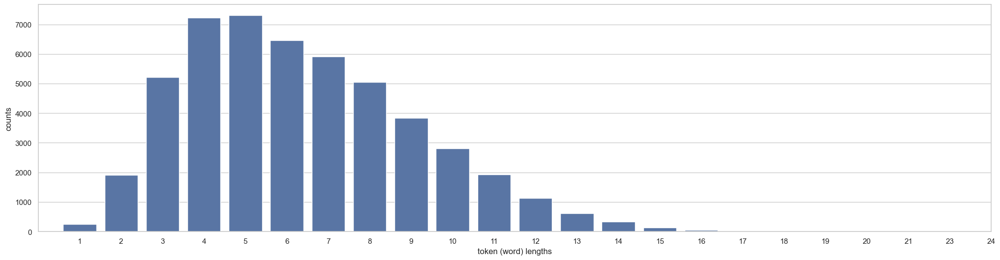

In [68]:
# get length of individual word (GPT2)

word_lengths = [len(word) for word in tokenizer_gpt2.vocab.keys()] # token length
uniques, counts = np.unique(word_lengths, return_counts=True)

plt.figure(figsize=(25, 6))
sns.barplot(x=uniques, y=counts)
plt.xlabel("token (word) lengths")
plt.ylabel("counts")
plt.xlim([-1, 22]);

Text(0, 0.5, 'counts')

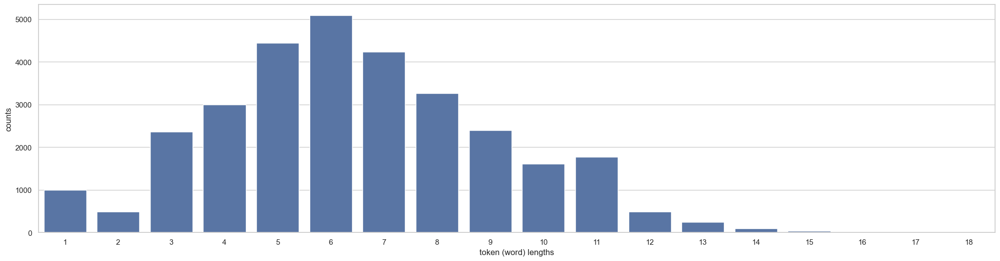

In [69]:
# get length of individual word (BERT)

word_lengths = [len(word) for word in tokenizer_bert.vocab.keys()] # token length
uniques, counts = np.unique(word_lengths, return_counts=True)

plt.figure(figsize=(25, 6))
sns.barplot(x=uniques, y=counts)
plt.xlabel("token (word) lengths")
plt.ylabel("counts")

In [77]:
# get word embeddings
embeddings_gpt2 = gpt2.wte.weight.detach().numpy()
embeddings_bert = bert.embeddings.word_embeddings.weight.detach().numpy()
print(embeddings_gpt2.shape, embeddings_bert.shape)

(50257, 768) (30522, 768)


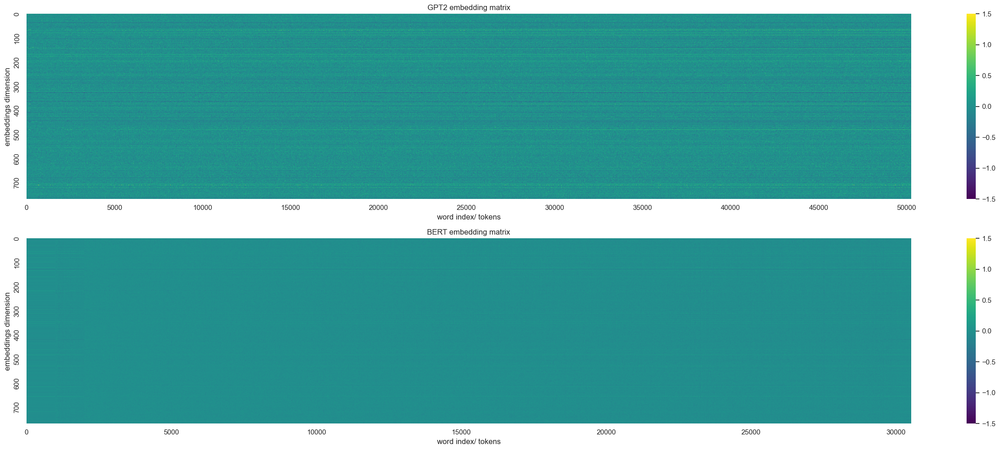

In [82]:
fig, ax = plt.subplots(nrows=2, ncols=1, figsize=(25, 10))
sns.heatmap(embeddings_gpt2.T, xticklabels=5000, yticklabels=100, vmin=-1.5, vmax=1.5, cmap="viridis", ax=ax[0])
ax[0].set_xlabel("word index/ tokens")
ax[0].set_ylabel("embeddings dimension")
ax[0].set_title("GPT2 embedding matrix")

sns.heatmap(embeddings_bert.T, xticklabels=5000, yticklabels=100, vmin=-1.5, vmax=1.5, cmap="viridis", ax=ax[1])
ax[1].set_xlabel("word index/ tokens")
ax[1].set_ylabel("embeddings dimension")
ax[1].set_title("BERT embedding matrix")

plt.tight_layout()

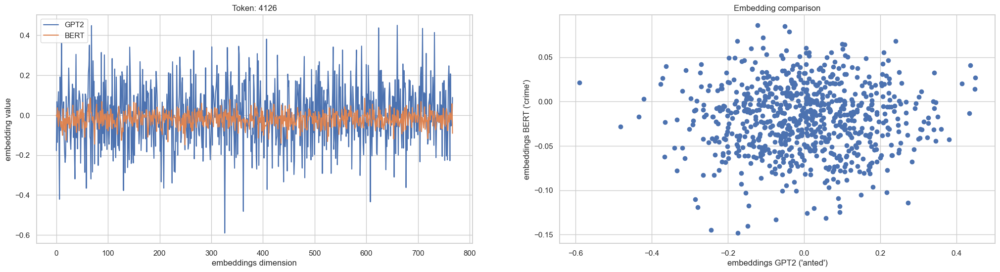

In [104]:
# comparing random token
np.random.seed(42)
random_idx = np.random.randint(3000, 5000)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(25, 6))
ax[0].plot(embeddings_gpt2[random_idx, :], label="GPT2")
ax[0].plot(embeddings_bert[random_idx, :], label="BERT")
ax[0].legend()
ax[0].set_xlabel("embeddings dimension")
ax[0].set_ylabel("embedding value")
ax[0].set_title(f"Token: {random_idx}")

ax[1].plot(embeddings_gpt2[random_idx, :], embeddings_bert[random_idx, :], "o")
ax[1].set_xlabel(f"embeddings GPT2 ('{tokenizer_gpt2.decode(random_idx)}')")
ax[1].set_ylabel(f"embeddings BERT ('{tokenizer_bert.decode(random_idx)}')")
ax[1].set_title("Embedding comparison");

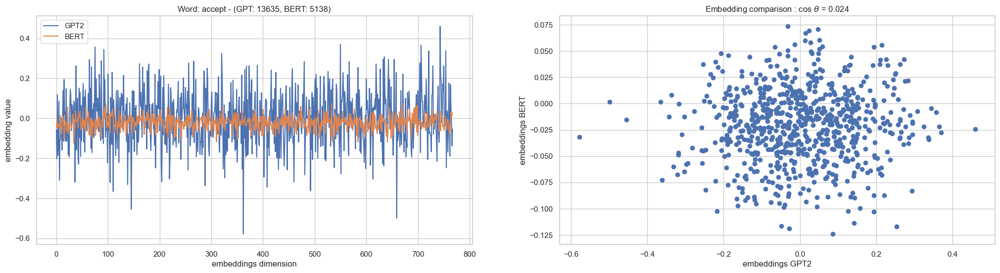

In [148]:
# comparing the same word


word = "accept"

token_idx_gpt2 = tokenizer_gpt2.encode(word)[0]
token_idx_bert = tokenizer_bert.encode(word, add_special_tokens=False)[0]

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(25, 6))
ax[0].plot(embeddings_gpt2[token_idx_gpt2, :], label="GPT2")
ax[0].plot(embeddings_bert[token_idx_bert, :], label="BERT")
ax[0].legend()
ax[0].set_xlabel("embeddings dimension")
ax[0].set_ylabel("embedding value")
ax[0].set_title(f"Word: {word} - (GPT: {token_idx_gpt2}, BERT: {token_idx_bert})")

ax[1].plot(embeddings_gpt2[token_idx_gpt2, :], embeddings_bert[token_idx_bert, :], "o")
ax[1].set_xlabel(f"embeddings GPT2")
ax[1].set_ylabel(f"embeddings BERT")
ax[1].set_title(rf"Embedding comparison : cos $\theta$ = {cosine_similarity(embeddings_gpt2[token_idx_gpt2, :], embeddings_bert[token_idx_bert, :])}");

(50257, 768) (30522, 768)


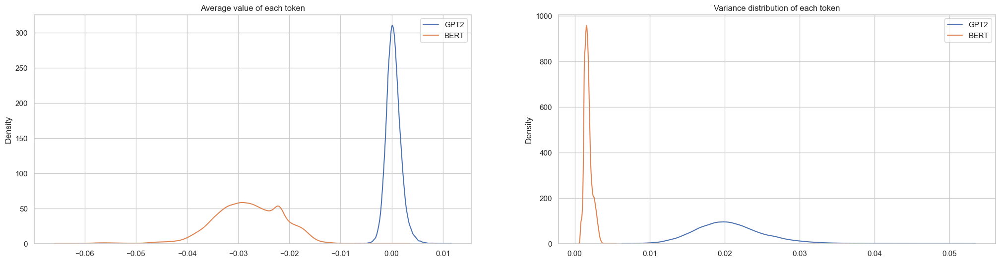

In [160]:
# distribution of embedding characteristics
# average and variability across all the dimensions
embeddings_gpt2 = gpt2.wte.weight.detach().numpy()
embeddings_bert = bert.embeddings.word_embeddings.weight.detach().numpy()
print(embeddings_gpt2.shape, embeddings_bert.shape)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(25, 6))
sns.kdeplot(embeddings_gpt2.mean(axis=1), ax=ax[0], label="GPT2")
sns.kdeplot(embeddings_bert.mean(axis=1), ax=ax[0], label="BERT")
ax[0].legend()
ax[0].set_title("Average value of each token")

sns.kdeplot(embeddings_gpt2.var(axis=1), ax=ax[1], label="GPT2")
sns.kdeplot(embeddings_bert.var(axis=1), ax=ax[1], label="BERT")
ax[1].legend()
ax[1].set_title("Variance distribution of each token");

### Doing basic arithmetic using tokens and embeddings

#### number to tokens

The number 0 is represented as token(s) [15]
The number 1 is represented as token(s) [16]
The number 2 is represented as token(s) [17]
The number 3 is represented as token(s) [18]
The number 4 is represented as token(s) [19]
The number 5 is represented as token(s) [20]
The number 6 is represented as token(s) [21]
The number 7 is represented as token(s) [22]
The number 8 is represented as token(s) [23]
The number 9 is represented as token(s) [24]
The number 10 is represented as token(s) [940]
The number 20 is represented as token(s) [1238]
The number 30 is represented as token(s) [1270]
The number 40 is represented as token(s) [1821]
The number 50 is represented as token(s) [1120]
The number 60 is represented as token(s) [1899]
The number 70 is represented as token(s) [2154]
The number 80 is represented as token(s) [1795]
The number 90 is represented as token(s) [3829]
The number 100 is represented as token(s) [3064]
The number 200 is represented as token(s) [2167]
The number 300 is rep

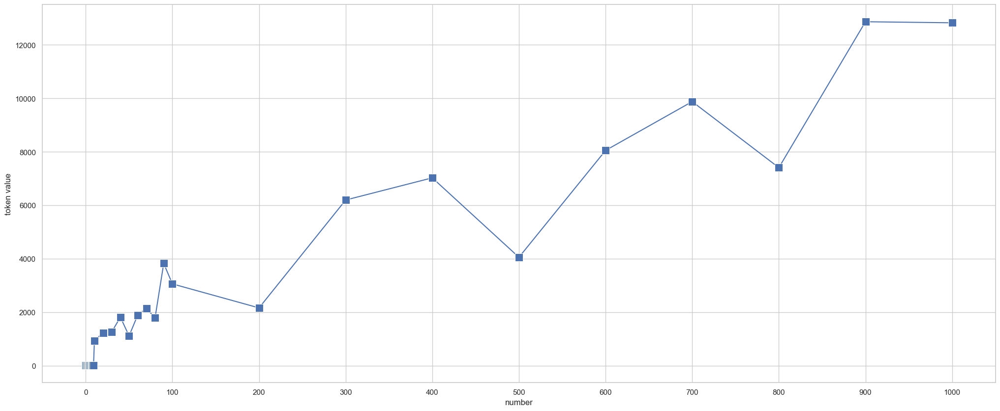

In [214]:


numbers = list(range(10)) + list(range(10, 100, 10)) + list(range(100, 1001, 100))

num2token = {str(n) : tokenizer_gpt2.encode(str(n)) for n in numbers}

for k, v in num2token.items():
    print(f"The number {k} is represented as token(s) {v}")

plt.figure(figsize=(25, 10))
sns.lineplot(x=numbers, y=[v[0] for v in num2token.values()], marker="s", markersize=12)
plt.xticks(range(0, 1001, 100))
plt.xlabel("number")
plt.ylabel("token value");

In [215]:
# number to tokens

numbers = list(range(10)) + list(range(10, 100, 10)) + list(range(100, 1001, 100))
numbers_2 = [n/2 for n in numbers]
num2token = {str(n) : tokenizer_gpt2.encode(str(n)) for n in numbers_2}

for k, v in num2token.items():
    print(f"The number {k} is represented as token(s) {v}")

The number 0.0 is represented as token(s) [15, 13, 15]
The number 0.5 is represented as token(s) [15, 13, 20]
The number 1.0 is represented as token(s) [16, 13, 15]
The number 1.5 is represented as token(s) [16, 13, 20]
The number 2.0 is represented as token(s) [17, 13, 15]
The number 2.5 is represented as token(s) [17, 13, 20]
The number 3.0 is represented as token(s) [18, 13, 15]
The number 3.5 is represented as token(s) [18, 13, 20]
The number 4.0 is represented as token(s) [19, 13, 15]
The number 4.5 is represented as token(s) [19, 13, 20]
The number 5.0 is represented as token(s) [20, 13, 15]
The number 10.0 is represented as token(s) [940, 13, 15]
The number 15.0 is represented as token(s) [1314, 13, 15]
The number 20.0 is represented as token(s) [1238, 13, 15]
The number 25.0 is represented as token(s) [1495, 13, 15]
The number 30.0 is represented as token(s) [1270, 13, 15]
The number 35.0 is represented as token(s) [2327, 13, 15]
The number 40.0 is represented as token(s) [1821

#### how long are numbers?

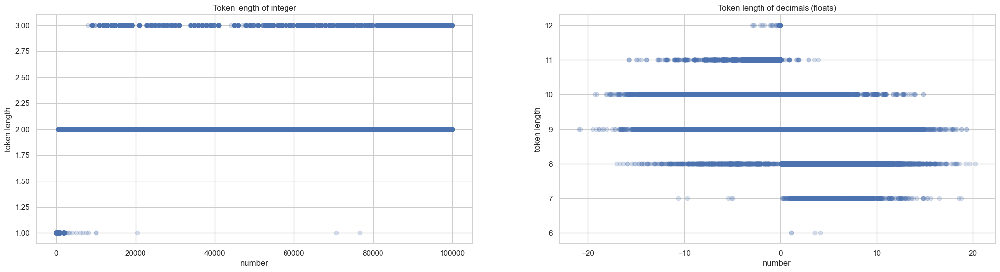

In [229]:
N = 100000
numbers_ints = (range(N))
token_length_ints = [len(tokenizer_gpt2.encode(str(n))) for n in numbers_ints] 

numbers_floats = np.random.normal(loc=0, scale=5, size=N)
token_length_floats = [len(tokenizer_gpt2.encode(str(n))) for n in numbers_floats] 

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(25, 6))
ax[0].plot(numbers_ints, token_length_ints, 'o', alpha=0.2)
ax[0].set_xlabel("number")
ax[0].set_ylabel("token length")
ax[0].set_title(f"Token length of integer")

ax[1].plot(numbers_floats, token_length_floats, 'o', alpha=0.2)
ax[1].set_xlabel("number")
ax[1].set_ylabel("token length")
ax[1].set_title(f"Token length of decimals (floats)");

#### does math work in token conversion?

In [238]:
eq = "5 x 3 ="
tokens = tokenizer_gpt2.encode(eq)
print(f"{eq}: {tokens}")
int(np.prod(tokens))

5 x 3 =: [20, 2124, 513, 796]


17346623040

#### does math work in embeddings?

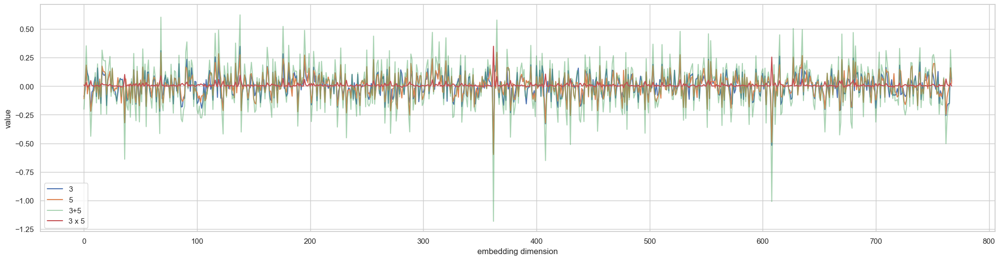

In [251]:
num1, num2 = str(3), str(5)
num1_token_id = tokenizer_gpt2.encode(num1)[0]  # [v for k, v in tokenizer_gpt2.vocab.items() if k == num1]
num2_token_id = tokenizer_gpt2.encode(num2)[0]

plt.figure(figsize=(25, 6))
plt.plot(embeddings_gpt2[num1_token_id, :], label=num1)
plt.plot(embeddings_gpt2[num2_token_id, :], label=num2)
plt.plot(embeddings_gpt2[num1_token_id, :] + embeddings_gpt2[num2_token_id, :], label=f"{num1}+{num2}", alpha=0.5)
plt.plot(embeddings_gpt2[num1_token_id, :] * embeddings_gpt2[num2_token_id, :], label=f"{num1} x {num2}")
plt.xlabel("embedding dimension")
plt.ylabel("value")
plt.legend()

In [264]:
h = embeddings_gpt2[num1_token_id, :] + embeddings_gpt2[num2_token_id, :]
logits = np.matmul(h, embeddings_gpt2.T)  # unembedding: h @ E.T -> score per vocab word
t_idx = np.argmax(logits)                  # pick highest-scoring token id
tokenizer_gpt2.decode(t_idx)               # decode token id back to text

'5'

In [265]:
h = embeddings_gpt2[num1_token_id, :] * embeddings_gpt2[num2_token_id, :] # hadamard multiplication

t_idx = np.argmax(np.matmul(h, embeddings_gpt2.T))
tokenizer_gpt2.decode(t_idx) 

' Weinstein'

## Cosine similarity versus Pearson correlation coefficient

In [279]:
r = lambda x, y : round(sum((x - x.mean()) * (y - y.mean()))/np.sqrt((sum((x-x.mean())**2) * sum((y-y.mean())**2))), 3)

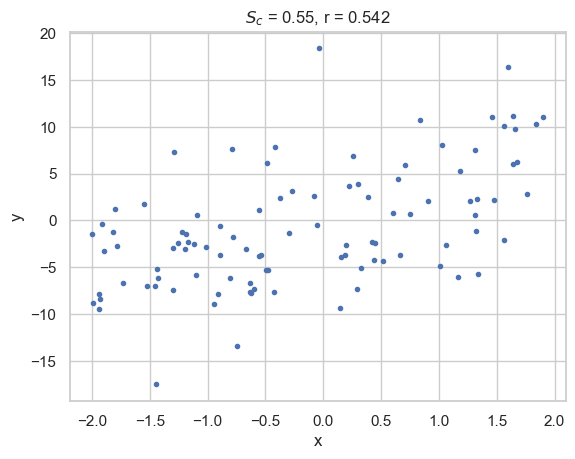

In [290]:
# with mean centered data

N_data = 100
x = np.random.uniform(low=-2, high=2, size=N_data)
y = 3*x 
y += 5*np.random.randn(N_data)

plt.plot(x, y, ".")
plt.xlabel("x")
plt.ylabel("y")

plt.title(rf"$S_c$ = {cosine_similarity(x, y)}, r = {r(x, y)}");

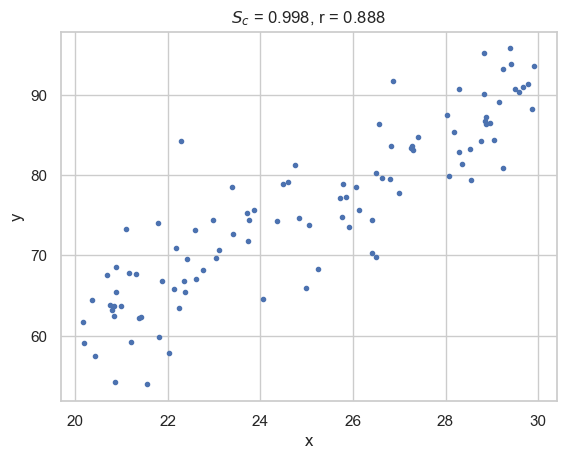

In [285]:
# with non-mean centered data

N_data = 100
x = np.random.uniform(low=20, high=30, size=N_data)
y = 3*x 
y += 5*np.random.randn(N_data)

plt.plot(x, y, ".")
plt.xlabel("x")
plt.ylabel("y")

plt.title(rf"$S_c$ = {cosine_similarity(x, y)}, r = {r(x, y)}");

In [291]:
torch.cosine_similarity(torch.tensor(x).reshape(1, -1), torch.tensor(y).reshape(1, -1))

tensor([0.5498], dtype=torch.float64)

In [292]:
torch.cosine_similarity(torch.tensor(x).view(1, -1), torch.tensor(y).view(1, -1))

tensor([0.5498], dtype=torch.float64)

#### Finding tokens with similar embeddings

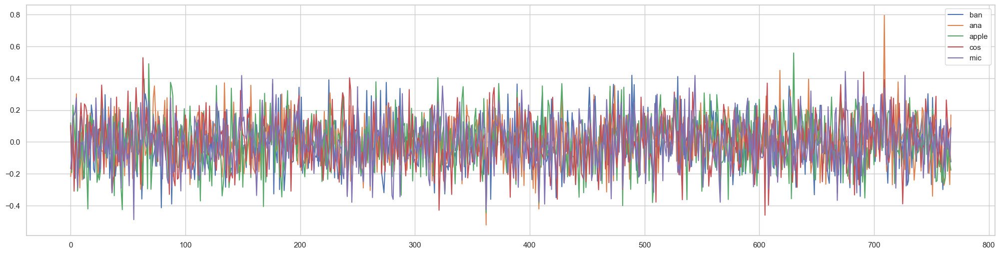

In [348]:
# the cosmic banana

def get_idx_and_vocab(word):
    idxs = tokenizer_gpt2.encode(word)
    return {tokenizer_gpt2.decode(idx): idx for idx in idxs}

words = ["banana", "apple", "cosmic"]
word2tokens = {word: get_idx_and_vocab(word) for word in words}

plt.figure(figsize=(25, 6))
for word, token_idxs in word2tokens.items():
    for token_label, token_idx in token_idxs.items():
        plt.plot(embeddings_gpt2[token_idx, :], label=token_label)
plt.legend()

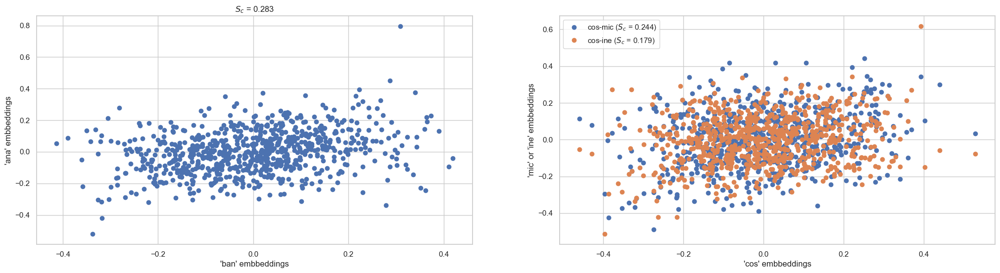

In [366]:
words.append("cosine")
flat_tokens = {}
for word in words:
    flat_tokens.update(get_idx_and_vocab(word))

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(25, 6))
subword1, subword2 = "ban", "ana" 
idx1, idx2 = flat_tokens[subword1], flat_tokens[subword2]
ax[0].plot(embeddings_gpt2[idx1, :], embeddings_gpt2[idx2, :], "o")
ax[0].set_xlabel(f"'{subword1}' embbeddings")
ax[0].set_ylabel(f"'{subword2}' embbeddings")
ax[0].set_title(rf"$S_c$ = {cosine_similarity(embeddings_gpt2[idx1, :], embeddings_gpt2[idx2, :])}")

subword1, subword2, subword3 = "cos", "mic", "ine" 
idx1, idx2, idx3 = flat_tokens[subword1], flat_tokens[subword2], flat_tokens[subword3]
ax[1].plot(embeddings_gpt2[idx1, :], embeddings_gpt2[idx2, :], "o", label=rf"{subword1}-{subword2} ($S_c$ = {cosine_similarity(embeddings_gpt2[idx1, :], embeddings_gpt2[idx2, :])})")
ax[1].plot(embeddings_gpt2[idx1, :], embeddings_gpt2[idx3, :], "o", label=rf"{subword1}-{subword3} ($S_c$ = {cosine_similarity(embeddings_gpt2[idx1, :], embeddings_gpt2[idx3, :])})")
ax[1].set_xlabel(f"'{subword1}' embbeddings")
ax[1].set_ylabel(f"'{subword2}' or '{subword3}' embbeddings")
ax[1].legend();

In [371]:
tokenizer_gpt2(target_word)["input_ids"][0]

[18040]

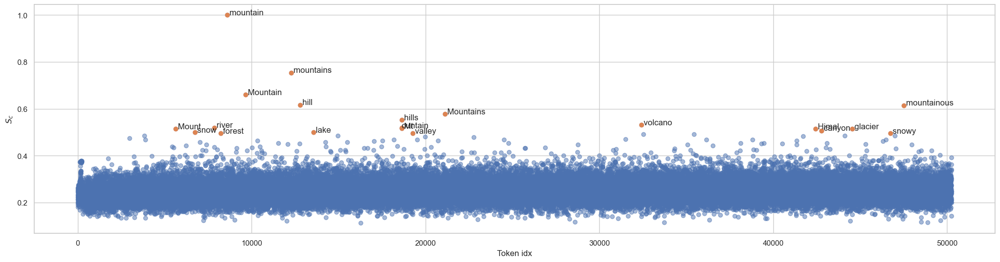

In [468]:
# find tokens with similar embeddings
target_word = " mountain"
target_idx = tokenizer_gpt2(target_word)["input_ids"][0]

Sc = []
token_idxs = []
for word, token_idx in tokenizer_gpt2.vocab.items():
    Sc.append(cosine_similarity(embeddings_gpt2[target_idx, :], embeddings_gpt2[token_idx, :]))
    token_idxs.append(token_idx)

sorted_idxs = np.argsort(Sc)[::-1][:20]
top20_Sc= np.array(Sc)[sorted_idxs]
top20_token_idxs = np.array(token_idxs)[sorted_idxs]

plt.figure(figsize=(25, 6))
plt.scatter(token_idxs, Sc, alpha=0.5)
plt.scatter(top20_token_idxs, top20_Sc)
for x, y in zip(top20_token_idxs, top20_Sc):
    label = tokenizer_gpt2.decode([x])
    plt.text(x, y, label)
plt.xlabel(f"Token idx")
plt.ylabel(rf"$S_c$");

In [469]:
for x, y in zip(top20_token_idxs, top20_Sc):
    print(f"'{tokenizer_gpt2.decode(x)}' has cosine similatiry of {y}")

' mountain' has cosine similatiry of 1.0
' mountains' has cosine similatiry of 0.754
' Mountain' has cosine similatiry of 0.66
' hill' has cosine similatiry of 0.617
' mountainous' has cosine similatiry of 0.615
' Mountains' has cosine similatiry of 0.578
' hills' has cosine similatiry of 0.553
' volcano' has cosine similatiry of 0.531
' river' has cosine similatiry of 0.52
'ountain' has cosine similatiry of 0.519
' Mt' has cosine similatiry of 0.517
' glacier' has cosine similatiry of 0.515
' Mount' has cosine similatiry of 0.514
' Himal' has cosine similatiry of 0.514
' canyon' has cosine similatiry of 0.507
' lake' has cosine similatiry of 0.5
' snow' has cosine similatiry of 0.499
' forest' has cosine similatiry of 0.496
' snowy' has cosine similatiry of 0.495
' valley' has cosine similatiry of 0.495


In [501]:
tokenizer_gpt2.vocab

50257

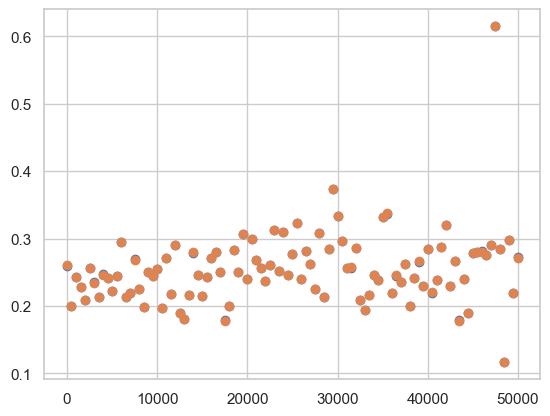

In [517]:
# using linear algebra
E = embeddings_gpt2/np.linalg.norm(embeddings_gpt2, axis=1, keepdims=True) # normalized embeddings

target_word = " mountain" # seed
target_idx = tokenizer_gpt2(target_word)["input_ids"][0]
target_vec = np.expand_dims(E[target_idx, :], 0)

# computing Sc using loop
Sc, token_idxs = [], []
for token_idx in range(len(embeddings_gpt2)):
    Sc.append(cosine_similarity(target_vec, embeddings_gpt2[token_idx, :]))
    token_idxs.append(token_idx)

Sc2 = (target_vec @ E.T).squeeze()

plt.scatter(token_idxs[::500], Sc[::500])
plt.scatter(token_idxs[::500], Sc2[::500])

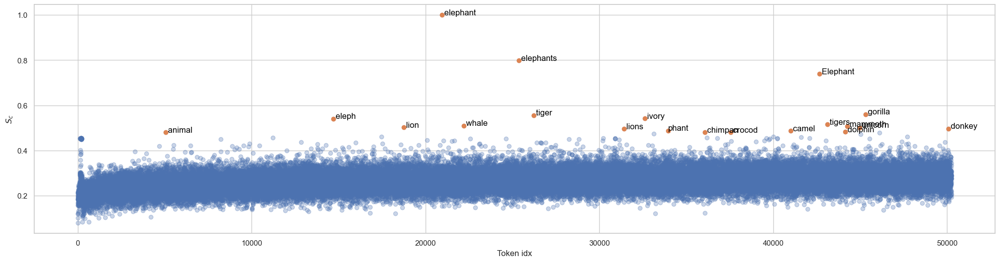

In [550]:
def find_similar_tokens(target):
    E = embeddings_gpt2/np.linalg.norm(embeddings_gpt2, axis=1, keepdims=True)
    target_idx = tokenizer_gpt2(target)["input_ids"][0]
    target_vec = np.expand_dims(E[target_idx, :], 0)

    

    cos_sim = (target_vec @ E.T).squeeze()
    token_idxs - np.arange(len(E))
    top20_idxs = np.argsort(cos_sim)[-20:]

    top20_cos_sim = cos_sim[top20_idxs]
    top20_token_idxs = np.arange(len(E))[top20_idxs]

    plt.figure(figsize=(25, 6))
    plt.scatter(token_idxs, cos_sim, alpha=0.3)
    plt.scatter(top20_token_idxs, top20_cos_sim)
    for x, y in zip(top20_token_idxs, top20_cos_sim):
        text = tokenizer_gpt2.decode(x)
        plt.text(x, y, text, color="black") # only text
    plt.xlabel(f"Token idx")
    plt.ylabel(rf"$S_c$");
    

find_similar_tokens(" elephant")

## Unembeddings

vector to tokens

In [558]:
gpt2 = GPT2Model.from_pretrained("gpt2")
tokenizer_gpt2 = GPT2Tokenizer.from_pretrained("gpt2")
embeddings_gpt2 = gpt2.wte.weight.detach().numpy()
gpt2.config

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

GPT2Config {
  "activation_function": "gelu_new",
  "add_cross_attention": false,
  "architectures": [
    "GPT2LMHeadModel"
  ],
  "attn_pdrop": 0.1,
  "bos_token_id": 50256,
  "dtype": "float32",
  "embd_pdrop": 0.1,
  "eos_token_id": 50256,
  "initializer_range": 0.02,
  "layer_norm_epsilon": 1e-05,
  "model_type": "gpt2",
  "n_ctx": 1024,
  "n_embd": 768,
  "n_head": 12,
  "n_inner": null,
  "n_layer": 12,
  "n_positions": 1024,
  "pad_token_id": null,
  "reorder_and_upcast_attn": false,
  "resid_pdrop": 0.1,
  "scale_attn_by_inverse_layer_idx": false,
  "scale_attn_weights": true,
  "summary_activation": null,
  "summary_first_dropout": 0.1,
  "summary_proj_to_labels": true,
  "summary_type": "cls_index",
  "summary_use_proj": true,
  "task_specific_params": {
    "text-generation": {
      "do_sample": true,
      "max_length": 50
    }
  },
  "tie_word_embeddings": true,
  "transformers_version": "5.15.0",
  "use_cache": true,
  "vocab_size": 50257
}

In [556]:
print(f"Embedding dimension: {gpt2.config.n_embd}")
print(f"Vocab size: {gpt2.config.vocab_size}")
print(f"Size of embedding mat: {embeddings_gpt2.shape}")

Embedding dimension: 768
Vocab size: 50257
Size of embedding mat: (50257, 768)


In [562]:
# real and random unembedding matrices
unembeddings_gpt2 = embeddings_gpt2.T
unembeddings_gpt2_random = np.random.randn(embeddings_gpt2.shape[1], embeddings_gpt2.shape[0])

In [626]:
# California embeddings

def find_top_tokens_idxs(dp, n=5):
    idxs = np.argsort(dp)[::-1][:n]
    return idxs
    

 California is encoded as [3442]


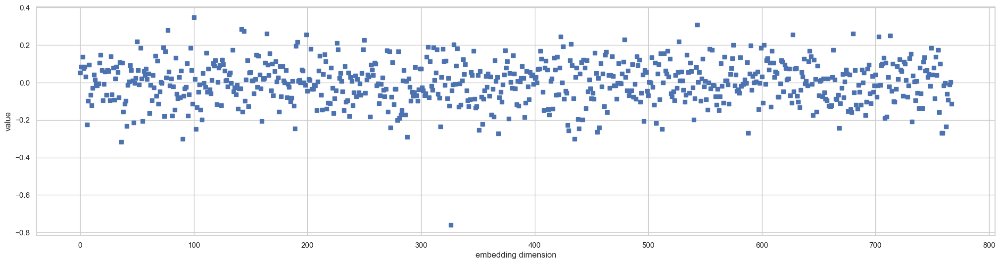

In [630]:
target = " California" # one token word
print(f"{target} is encoded as {tokenizer_gpt2.encode(target)}")
target_idx = tokenizer_gpt2(target)["input_ids"][0]
target_embeddings = embeddings_gpt2[target_idx, :]

plt.figure(figsize=(25, 6))
plt.plot(target_embeddings, "s")
plt.xlabel("embedding dimension")
plt.ylabel("value");

 California has the largest dot product with token 25284: California

Dot product of 10.14 for token 25284 - California
Dot product of 9.617 for token 3442 -  California
Dot product of 8.816 for token 37704 -  Californ
Dot product of 8.088 for token 19619 - Calif
Dot product of 7.718 for token 3192 -  Calif
Dot product of 7.359 for token 12087 -  Nevada
Dot product of 7.158 for token 40732 - Arizona
Dot product of 7.151 for token 41330 - Colorado
Dot product of 6.974 for token 31135 - Florida
Dot product of 6.912 for token 41243 - Oregon


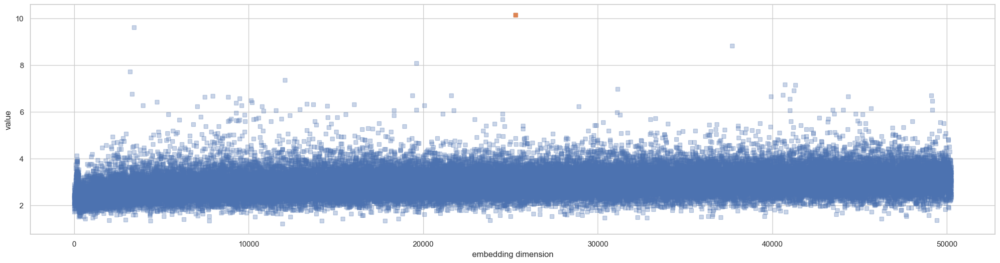

In [633]:
dot_product = np.expand_dims(target_embeddings, 0) @ unembeddings_gpt2
idx_ = np.argmax(dot_product.squeeze())
print(f"{target} has the largest dot product with token {idx_}: {tokenizer_gpt2.decode(idx_)}")

plt.figure(figsize=(25, 6))
plt.plot(dot_product.flatten(), "s", alpha=0.3)
plt.plot(idx_, dot_product.flatten()[idx_], "s")
plt.xlabel("embedding dimension")
plt.ylabel("value");

print()

top_idxs = find_top_tokens_idxs(dot_product.flatten(), n=10)
for idx in top_idxs:
    print(f"Dot product of {dot_product.flatten()[idx]:.4} for token {idx} - {tokenizer_gpt2.decode(idx)}")

 California has the largest dot product with token 33807: ansen


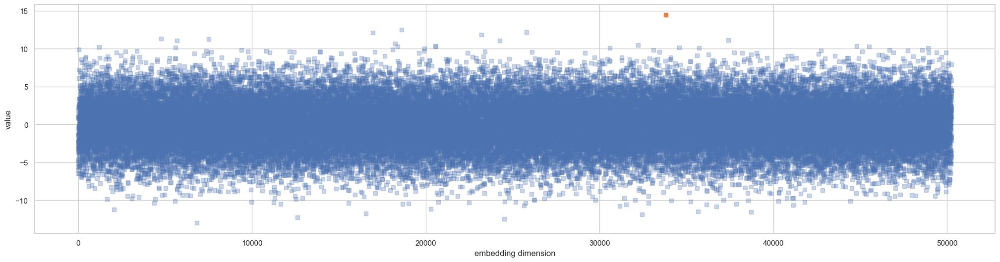

In [632]:
dot_product_random = np.expand_dims(target_embeddings, 0) @ unembeddings_gpt2_random
idx_ = np.argmax(dot_product_random.squeeze())
print(f"{target} has the largest dot product with token {idx_}: {tokenizer_gpt2.decode(idx_)}")

plt.figure(figsize=(25, 6))
plt.plot(dot_product_random.flatten(), "s", alpha=0.3)
plt.plot(idx_, dot_product_random.flatten()[idx_], "s")
plt.xlabel("embedding dimension")
plt.ylabel("value");

In [635]:
np.linalg.norm(embeddings_gpt2[3442, :])

np.float32(3.1011093)

In [636]:
np.linalg.norm(embeddings_gpt2[target_idx, :])

np.float32(3.1011093)

In [637]:
np.linalg.norm(embeddings_gpt2[41243, :])

np.float32(4.053989)

In [638]:
np.dot(embeddings_gpt2[41243, :], embeddings_gpt2[target_idx, :])

np.float32(6.9119143)

In [645]:
a = [2.5, 1.5]
np.dot(a, a)

np.float64(8.5)

In [650]:
b = [4, 5]

np.dot(b, b)

np.int64(41)

In [649]:
np.dot(a, b)

np.float64(17.5)

In [647]:
cosine_similarity(a, b)

0.937

In [648]:
cosine_similarity(a, a)

1.0

In [677]:
# generate a token sequence
def find_top_tokens(dp, n=5):
    idxs = np.argsort(dp)[::-1][:n]
    return [tokenizer_gpt2.decode(idx) for idx in idxs]

def generate_token_sequence(seed, sequence_length=10):
    sequence = [seed]
    while len(sequence) < sequence_length:    
        seed_id = tokenizer_gpt2(sequence[-1])["input_ids"][0]
        target_embeddings = embeddings_gpt2[seed_id, :]
        
        dot_product = (np.expand_dims(target_embeddings, 0) @ unembeddings_gpt2).squeeze()
        sequence.append(np.random.choice(find_top_tokens(dot_product, 10)))
    return "".join(sequence)
    
generate_token_sequence("mountain")

'mountainconservancybudgetsoDeliveryDateconservancyconservancy budgets budgetusterityconservancy'

In [680]:
# with unembeddings_gpt2_random

def generate_token_sequence(seed, sequence_length=10):
    sequence = [seed]
    while len(sequence) < sequence_length:    
        seed_id = tokenizer_gpt2(sequence[-1])["input_ids"][0]
        target_embeddings = embeddings_gpt2[seed_id, :]
        
        dot_product = (np.expand_dims(target_embeddings, 0) @ unembeddings_gpt2_random).squeeze()
        sequence.append(np.random.choice(find_top_tokens(dot_product, 10)))
    return "".join(sequence)
    
generate_token_sequence("mountain", 10)

'mountainPrint pregnantPrint pregnant pregnantPrint Tr pregnantPrint'

# Positional Embeddings

## intro

In [684]:
pos_embeddings = gpt2.wpe.weight.detach().numpy()
pos_embeddings.shape # token_pos x dim

(1024, 768)

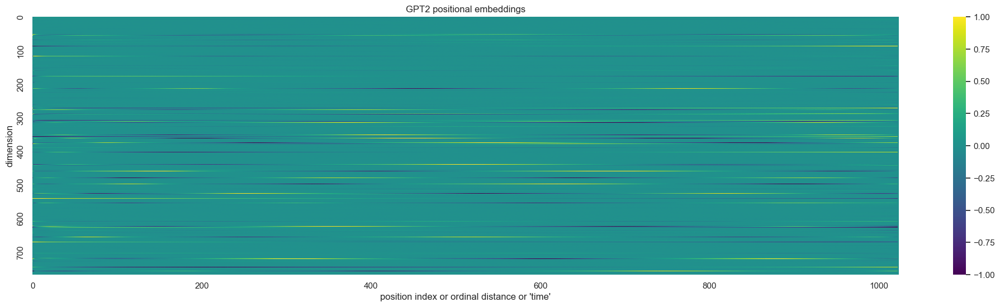

In [752]:
plt.figure(figsize=(25, 6))
sns.heatmap(pos_embeddings.T, xticklabels=200, yticklabels=100, cmap="viridis", vmin=-1, vmax=1)
plt.xlabel("position index or ordinal distance or 'time'") # which position vector?
plt.ylabel("dimension")
plt.title("GPT2 positional embeddings");

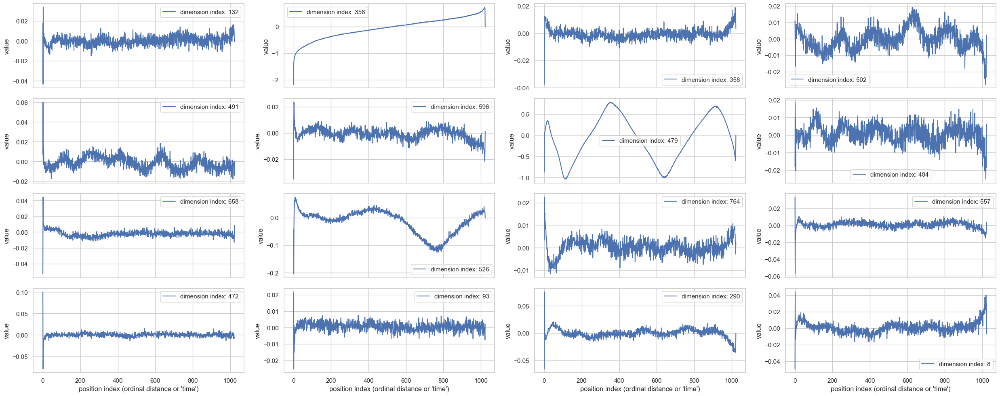

In [770]:
# plotting 16 random dimensions of the position embedding matrix, across all positions

np.random.seed(22)
dim_idxs = np.random.choice(pos_embeddings.shape[1], 16)

fig, ax = plt.subplots(nrows=4, ncols=4, figsize=(25, 10), sharex=True)
ax = ax.flatten()
for i, dim_idx in enumerate(dim_idxs):
    sns.lineplot(pos_embeddings[:, dim_idx], ax=ax[i], label=f"dimension index: {dim_idx}")
    ax[i].set_xlabel("position index (ordinal distance or 'time')")
    ax[i].set_ylabel("value")
plt.tight_layout()

# interpretations:
# high temporal frequencies (more fluctuations/ noiser) and low temporal frequencies

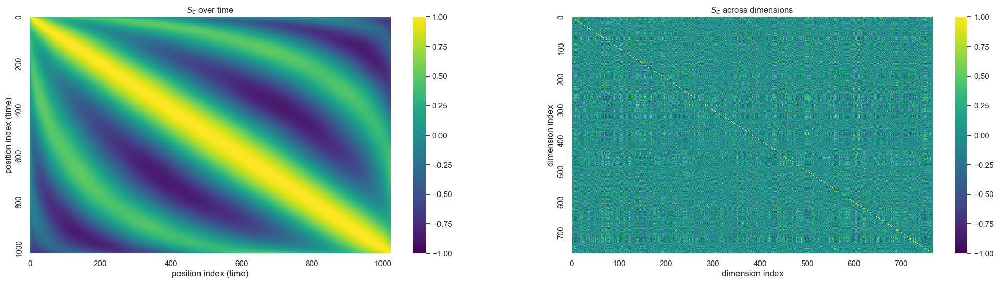

In [818]:
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(25, 6))

p = pos_embeddings/ np.linalg.norm(pos_embeddings, axis=1, keepdims=True)
cos_sim_positions = p @ p.T
sns.heatmap(cos_sim_positions, ax=ax[0], xticklabels=200, yticklabels=200, cmap="viridis", vmin=-1, vmax=1)
ax[0].set_xlabel("position index (time)")
ax[0].set_ylabel("position index (time)")
ax[0].set_title(r"$S_c$ over time")

# Normalized position embedding vector
p = pos_embeddings/ np.linalg.norm(pos_embeddings, axis=0, keepdims=True)
cos_sim_dims = p.T @ p
sns.heatmap(cos_sim_dims, ax=ax[1], xticklabels=100, yticklabels=100, cmap="viridis", vmin=-1, vmax=1) # all of these vectors are uncorrelated with eachother Sc close to ZERO
ax[1].set_xlabel("dimension index")
ax[1].set_ylabel("dimension index")
ax[1].set_title(r"$S_c$ across dimensions");

In [785]:
2*i

768

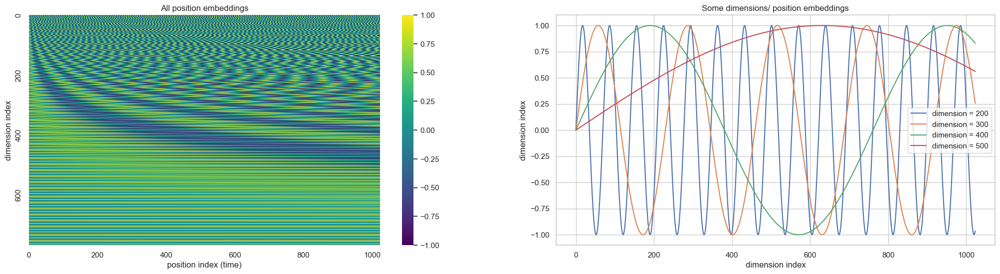

In [796]:
# sinusoidal embeddings
pos_embeddings_formula = np.zeros(pos_embeddings.shape)
d_model = pos_embeddings_formula.shape[1]
for pos in range(pos_embeddings_formula.shape[0]):
    for i in range(d_model//2):
        theta = pos/10000**(2*i/d_model)
        if i % 2 == 0:
            pos_embeddings_formula[pos, 2*i] = np.sin(theta)
        else:
            pos_embeddings_formula[pos, 2*i+1] = np.cos(theta)

idxs = [200, 300, 400, 500]

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(25, 6))
sns.heatmap(pos_embeddings_formula.T, ax=ax[0], xticklabels=200, yticklabels=200, cmap="viridis", vmin=-1, vmax=1)
ax[0].set_xlabel("position index (time)")
ax[0].set_ylabel("dimension index")
ax[0].set_title("All position embeddings")

for idx in idxs:
    sns.lineplot(pos_embeddings_formula[:, idx], ax=ax[1], label=f"dimension = {idx}")
ax[1].legend()
ax[1].set_xlabel("dimension index")
ax[1].set_ylabel("dimension index")
ax[1].set_title("Some dimensions/ position embeddings");

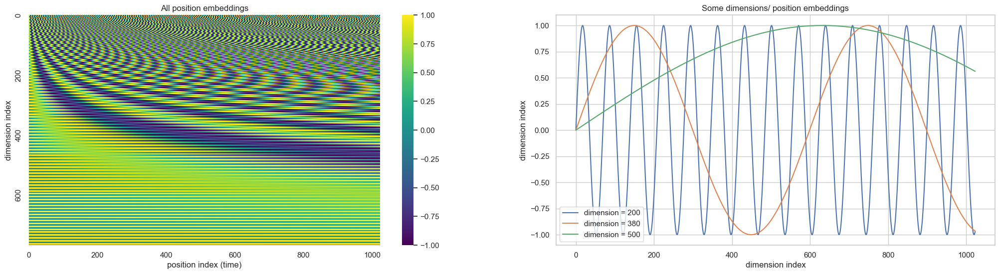

In [812]:
# faster
context_len, d_model = 1024, 768
pos_embeddings_formula = np.zeros((context_len, d_model))

for i in range(0, d_model, 2):
    theta = np.arange(context_len)/10000**(i/d_model)
    pos_embeddings_formula[:, i] = np.sin(theta)
    pos_embeddings_formula[:, i+1] = np.cos(theta)

idxs = [200, 380, 500]

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(25, 6))
sns.heatmap(pos_embeddings_formula.T, ax=ax[0], xticklabels=200, yticklabels=200, cmap="viridis", vmin=-1, vmax=1)
ax[0].set_xlabel("position index (time)")
ax[0].set_ylabel("dimension index")
ax[0].set_title("All position embeddings")

for idx in idxs:
    sns.lineplot(pos_embeddings_formula[:, idx], ax=ax[1], label=f"dimension = {idx}")
ax[1].legend()
ax[1].set_xlabel("dimension index")
ax[1].set_ylabel("dimension index")
ax[1].set_title("Some dimensions/ position embeddings");

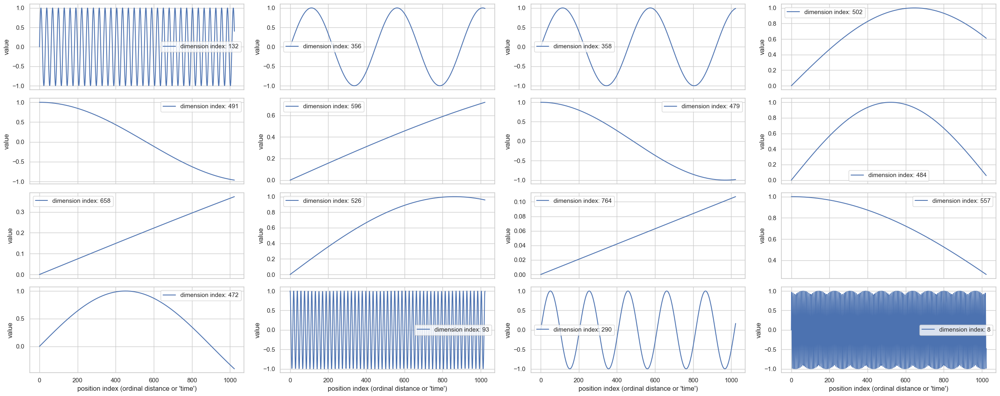

In [813]:
# plotting 16 random dimensions of the position embedding matrix, across all positions

np.random.seed(22)
dim_idxs = np.random.choice(pos_embeddings_formula.shape[1], 16)

fig, ax = plt.subplots(nrows=4, ncols=4, figsize=(25, 10), sharex=True)
ax = ax.flatten()
for i, dim_idx in enumerate(dim_idxs):
    sns.lineplot(pos_embeddings_formula[:, dim_idx], ax=ax[i], label=f"dimension index: {dim_idx}")
    ax[i].set_xlabel("position index (ordinal distance or 'time')")
    ax[i].set_ylabel("value")
plt.tight_layout()

# interpretations:
# high temporal frequencies (more fluctuations/ noiser) and low temporal frequencies

## Cosine similarity within the position embeddings

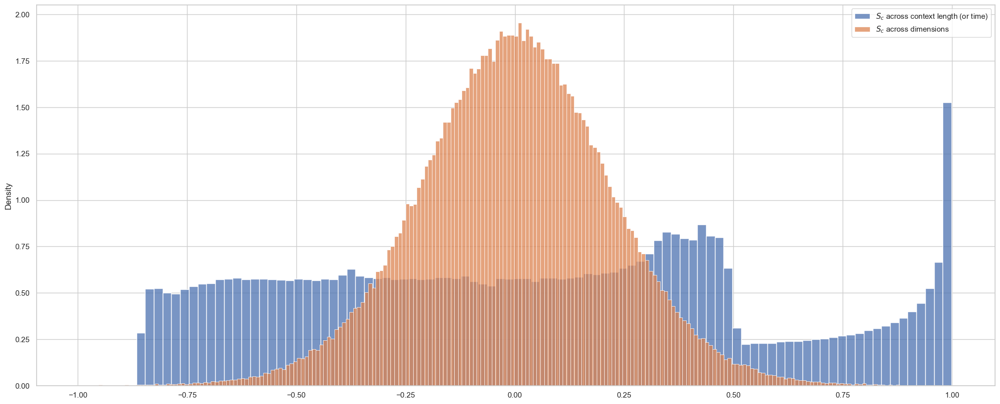

In [853]:
p = pos_embeddings/ np.linalg.norm(pos_embeddings, axis=1, keepdims=True)
cos_sim_positions = p @ p.T

p = pos_embeddings/ np.linalg.norm(pos_embeddings, axis=0, keepdims=True)
cos_sim_dims = p.T @ p

unique_cos_sim_positions = cos_sim_positions[np.nonzero(np.triu(cos_sim_positions, 1))]
unique_cos_sim_dims = cos_sim_dims[np.nonzero(np.triu(cos_sim_dims, 1))]

plt.figure(figsize=(25, 10))
sns.histplot(unique_cos_sim_positions, stat='density', label=r"$S_c$ across context length (or time)")
sns.histplot(unique_cos_sim_dims, stat='density', label=r"$S_c$ across dimensions")
plt.legend()

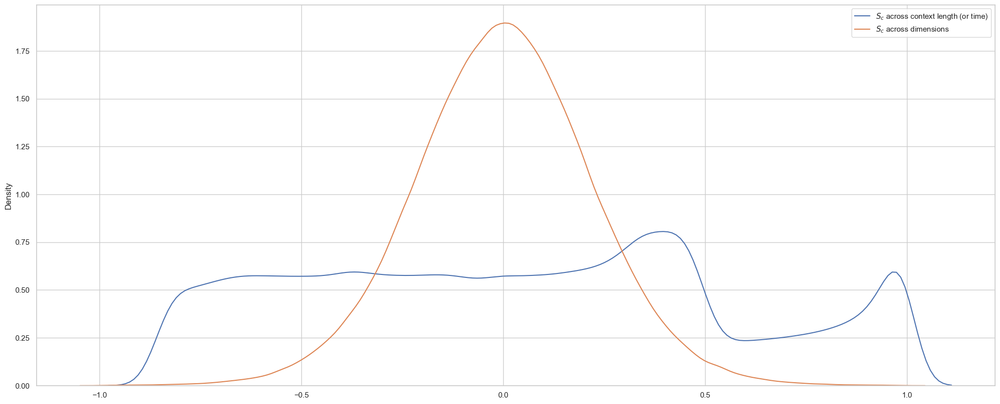

In [851]:
plt.figure(figsize=(25, 10))
sns.kdeplot(unique_cos_sim_positions, label=r"$S_c$ across context length (or time)")
sns.kdeplot(unique_cos_sim_dims, label=r"$S_c$ across dimensions")
plt.legend()

# Training embeddings from scratch

In [10]:
url = "https://www.gutenberg.org/files/35/35-0.txt"
text = preprocess(requests.get(url).text)
print(text[:1000])

start of the project gutenberg ebook the time machine an invention by wells contents introduction ii the machine iii the time traveller returns iv time travelling in the golden age vi the sunset of mankind vii sudden shock viii explanation ix the morlocks when night came xi the palace of green porcelain xii in the darkness xiii the trap of the white sphinx xiv the further vision xv the time traveller return xvi after the story epilogue introduction the time traveller for so it will be convenient to speak of him was expounding recondite matter to us his grey eyes shone and twinkled and his usually pale face was flushed and animated the fire burnt brightly and the soft radiance of the incandescent lights in the lilies of silver caught the bubbles that flashed and passed in our glasses our chairs being his patents embraced and caressed us rather than submitted to be sat upon and there was that luxurious after dinner atmosphere when thought runs gracefully free of the trammels of precision

In [11]:
len(text)

169874

In [12]:
words = text.split()

vocab = sorted(set(words))

n_words = len(words)
n_vocab = len(vocab)

word2idx = {word : i for i, word in enumerate(vocab)}
idx2word = {i : word for i, word in enumerate(vocab)}

print(f"Total words: {n_words}, unique words: {n_vocab}")

Total words: 30699, unique words: 4589


In [13]:
print(vocab[:10])

['abandon', 'abandoned', 'able', 'abnormally', 'abominable', 'abominations', 'about', 'above', 'abruptly', 'absence']


## parameters for the dataset

In [14]:
context_length, stride = 8, 2

inputs, targets = [], []
for i in range(0, n_words-context_length, stride):
    input_seq = words[i: i+context_length]
    target_seq = words[i+1: i+1+context_length]

    inputs.append([word2idx[word] for word in input_seq])
    targets.append([word2idx[word] for word in target_seq])

print(len(inputs))

print(inputs[123])
print(targets[123])

15346
[4304, 4119, 342, 4296, 3388, 1474, 131, 209]
[4119, 342, 4296, 3388, 1474, 131, 209, 2907]


## translating to Dataset/DataLoader format

In [240]:
class WordDataset(Dataset):
    def __init__(self, words, word2idx, context_length=8, stride=4):
        self.inputs, self.targets = [], []
        self.word2idx = word2idx

        for i in range(0, len(words)-context_length, stride):
            input_seq = words[i: i+context_length]
            target_seq = words[i+1: i+1+context_length]
        
            self.inputs.append(torch.tensor([word2idx[word] for word in input_seq]))
            self.targets.append(torch.tensor([word2idx[word] for word in target_seq]))

    def __len__(self):
        return len(self.inputs)

    def __getitem__(self, idx):
        return self.inputs[idx], self.targets[idx]

context_length, stride = 6, 3
words_dataset = WordDataset(words=words, word2idx=word2idx, context_length=context_length, stride=stride)
print(len(words_dataset))
print(words_dataset[22])

10231
(tensor([4371, 4567, 4042, 4109, 4171, 3306]), tensor([4567, 4042, 4109, 4171, 3306, 4568]))


In [241]:
dl = DataLoader(dataset=words_dataset, batch_size=32, shuffle=True, drop_last=True)

for i, (X, y) in enumerate(dl):
    if i == 3:
        break
    print(f"{i}:")
    print(f"Inputs shape: {X.shape}")
    print(f"Targets shape: {y.shape}")
    print()
    

0:
Inputs shape: torch.Size([32, 6])
Targets shape: torch.Size([32, 6])

1:
Inputs shape: torch.Size([32, 6])
Targets shape: torch.Size([32, 6])

2:
Inputs shape: torch.Size([32, 6])
Targets shape: torch.Size([32, 6])



In [242]:
# alternate way

loader = DataLoader(words_dataset, batch_size=32, shuffle=True, drop_last=True)
batch_x, batch_y = next(iter(loader))
print(batch_x.shape)
print(batch_y.shape)

torch.Size([32, 6])
torch.Size([32, 6])


In [243]:
X

tensor([[1815, 4546, 4082,  137, 4041, 4042],
        [ 151, 2465, 1744, 4295,   71, 4109],
        [4042, 2339, 2731, 4042, 3341, 2563],
        [  96, 1568, 2186, 2468,  319, 2731],
        [1902,  137, 4051,  137,   74, 3397],
        [2764, 2740, 4042, 2327, 2041,  571],
        [1902,  255, 4041, 4253,  255, 4042],
        [1901,  215, 3363, 2608, 2637,  137],
        [3608, 4042, 2572, 3905, 1572, 2106],
        [2400,  213,  585, 2630, 4042, 1487],
        [1888,  331, 2731, 4466, 4428, 4306],
        [4534,  501,  519, 2818, 4119, 4042],
        [3388, 4042, 4109, 4171, 4401, 3715],
        [2120, 2897, 1824, 4042, 3039,  821],
        [1500, 4571, 2739,  621,  235, 2470],
        [2816,  137, 2347,  413, 4296, 4042],
        [1868, 2243, 2731, 3146,  724, 2731],
        [2638, 3261,  137, 4043, 3393, 4076],
        [2608,  177, 2783, 2731,   96, 2999],
        [  74,  137, 2305, 4042, 4254,  101],
        [3669, 4478, 2590,  844, 4510, 2270],
        [4352, 3137, 4134, 2608, 1

## common heuristic in NLP

size of dimension ~ 100

In [244]:
float(np.sqrt(n_words))

175.21130100538608

In [245]:
emb_dim_train = int(((np.sqrt(n_words)) // 100)*100)
emb_dim_train

100

In [246]:
GPT2 = [gpt2.config.vocab_size, gpt2.config.n_embd] # GPT2 parameters
print(GPT2)

[50257, 768]


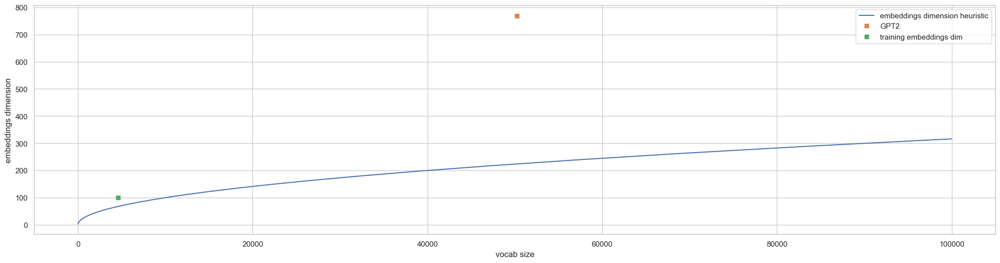

In [247]:
vocab_sizes = np.logspace(1, 5)
# emb_dim_heuristic  
d = np.sqrt(vocab_sizes)

d_train = int(((np.sqrt(n_words)) // 100)*100)

plt.figure(figsize=(25, 6))
plt.plot(vocab_sizes , d, label="embeddings dimension heuristic")
plt.plot(GPT2[0], GPT2[1], "s", label="GPT2")
plt.plot(n_vocab, d_train, "s", label="training embeddings dim")
plt.xlabel("vocab size")
plt.ylabel("embeddings dimension")
plt.legend()

In [249]:
# embeddings layer
d_train = 100 # arbitrary
embeddings_layer = nn.Embedding(num_embeddings=n_vocab, embedding_dim=d_train)
embeddings_layer.weight.shape

torch.Size([4589, 100])

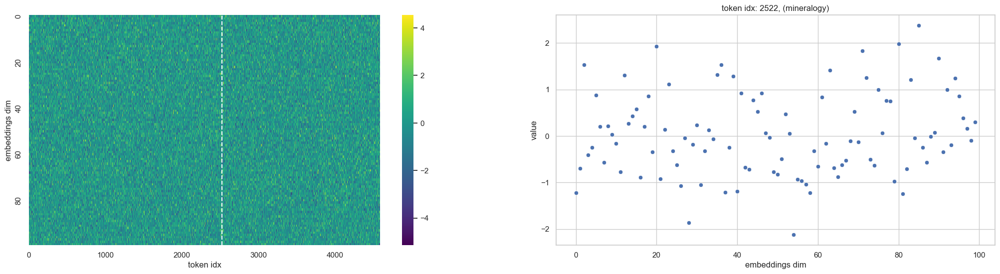

In [250]:
np.random.seed(20)
random_idx = np.random.choice(n_vocab)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(25, 6))
sns.heatmap(embeddings_layer.weight.detach().numpy().T, ax=ax[0], cmap="viridis", xticklabels=1000, yticklabels=20)
ax[0].set_xlabel("token idx")
ax[0].set_ylabel("embeddings dim")
ax[0].axvline(x=random_idx, color="white", linestyle="--")

sns.scatterplot(x=range(d_train), y=embeddings_layer.weight.detach().numpy()[random_idx, :], ax=ax[1])
ax[1].set_title(f"token idx: {random_idx}, ({idx2word[random_idx]})")
ax[1].set_xlabel("embeddings dim")
ax[1].set_ylabel("value");

In [252]:
# cosine similarity between words
cosine_similarity = lambda v1, v2: round(float(np.dot(np.ravel(v1), np.ravel(v2)) / (np.linalg.norm(v1) * np.linalg.norm(v2))), 3)
get_embeddings = lambda word : embeddings_layer.weight.detach().numpy()[word2idx[word], :]

word1, word2 = "time", "machine"

cosine_similarity(get_embeddings(word1), get_embeddings(word2))

0.061

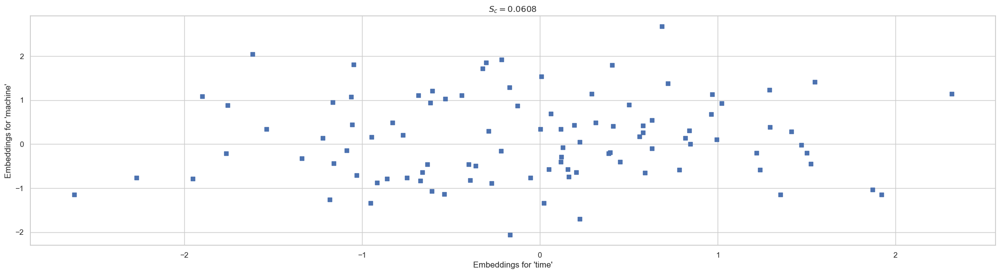

In [253]:
# using pytorch

cosine_similarity_torch = lambda embed1, embed2 : torch.dot(embed1, embed2)/(torch.norm(embed1)*torch.norm(embed2))

get_embeddings = lambda word : embeddings_layer.weight.detach()[word2idx[word], :]

sc = cosine_similarity_torch(get_embeddings(word1), get_embeddings(word2))

plt.figure(figsize=(25, 6))
plt.scatter(get_embeddings(word1), get_embeddings(word2), marker='s')
plt.xlabel(f"Embeddings for '{word1}'")
plt.ylabel(f"Embeddings for '{word2}'")
plt.title(rf"$S_c = {sc:0.3}$");

### building the model

In [254]:
class EmbeddingsModel(nn.Module):
    def __init__(self, vocab_size, embedding_dim, context_size):
        super().__init__()

        # embedding layer
        self.embeddings = nn.Embedding(vocab_size, embedding_dim) # builds the look-up table: shape as (vocab_size, embedding_dim) # (input_dims, output_dims)

        # hidden layer
        self.linear1 = nn.Linear(context_size*embedding_dim, 128)
        self.linear2 = nn.Linear(128, vocab_size)

    def forward(self, x): # initially x.shape = (batch_size, context_size) 
        embeds = self.embeddings(x).view(x.shape[0], -1) # shape: (batch_size, context_size, embedding_dim) -> (batch_size, context_size*embedding_dim) # flattened and ready to go to linear layer
        out = F.relu(self.linear1(embeds)) # shape: (batch_size, 128)
        out = self.linear2(out) # shape: (batch, vocab)

        return F.log_softmax(out, dim=1)
        
    

model = EmbeddingsModel(vocab_size=n_vocab, embedding_dim=100, context_size=6)
print(model)

EmbeddingsModel(
  (embeddings): Embedding(4589, 100)
  (linear1): Linear(in_features=600, out_features=128, bias=True)
  (linear2): Linear(in_features=128, out_features=4589, bias=True)
)


### testing the model

In [257]:
print("Output from the model:")
model.eval()

Output from the model:


EmbeddingsModel(
  (embeddings): Embedding(4589, 100)
  (linear1): Linear(in_features=600, out_features=128, bias=True)
  (linear2): Linear(in_features=128, out_features=4589, bias=True)
)

In [258]:
X, y = next(iter(dl))
print(f"Input (X) shape: {X.detach().numpy().shape}")
print(f"Input (y) shape: {y.detach().numpy().shape}")
print()
model_output = model(X)
print(f"Output shape: {model_output.detach().numpy().shape}")

Input (X) shape: (32, 6)
Input (y) shape: (32, 6)

Output shape: (32, 4589)


In [259]:
# softmax versus log softmax output

print(model_output[0].detach()) # output of the first batch

# model_output[0].detach().sum() # use this for the softmax output

torch.exp(model_output[0].detach()).sum()

tensor([-8.2766, -8.6888, -8.4359,  ..., -8.7325, -9.1040, -8.3363])


tensor(1.)

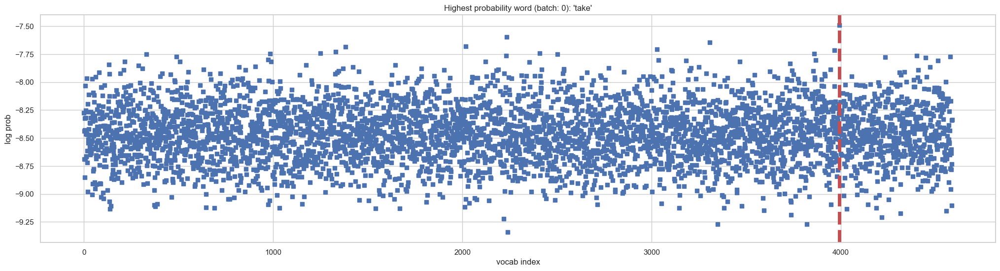

In [260]:
# word with highest probability
batch = 0
idx = model_output[batch].detach().numpy().argmax() # same: model_output[0].argmax().item()
word_ = idx2word[idx]
plt.figure(figsize=(25, 6))
plt.plot(model_output[0].detach(), "s")
plt.axvline(x=idx, color="r", ls="--", lw=5)
plt.title(f"Highest probability word (batch: {batch}): '{word_}'")
plt.xlabel("vocab index")
plt.ylabel("log prob");

In [261]:
print(f"Model input (batch {batch}): {[idx.item() for idx in X[batch]]} :: {[idx2word[idx.item()] for idx in X[batch]]}")
print(f"Model input (batch {batch}): {idx2word[model_output[0].argmax().item()]}")

Model input (batch 0): [4051, 4408, 2689, 4119, 1434, 137] :: ['there', 'was', 'nothing', 'to', 'fear', 'and']
Model input (batch 0): take


In [287]:
batch = np.random.choice(32)
X, y = next(iter(dl))

print(f"Input (batch): {batch}")
print(X[batch], end=" -> ")
print(" ".join([idx2word[idx.item()] for idx in X[batch]]))
print()
for i in range(context_length):
    print(f"Seq {i}: {" ".join([idx2word[idx.item()] for idx in X[batch]])}", end=" -> ")
    Y = model(X)
    new_token_idx = Y[batch].argmax().item()
    print(idx2word[new_token_idx])
    X[batch] = torch.concatenate((X[batch][1:], torch.tensor([new_token_idx])))
    

print(f"\n\nOutput (batch): {batch}")
print(" ".join([idx2word[idx.item()] for idx in X[batch]]))

Input (batch): 11
tensor([1344, 1838, 4042,  472, 2832, 3916]) -> expected happened the bronze panels suddenly

Seq 0: expected happened the bronze panels suddenly -> convulsively
Seq 1: happened the bronze panels suddenly convulsively -> amorous
Seq 2: the bronze panels suddenly convulsively amorous -> restlessness
Seq 3: bronze panels suddenly convulsively amorous restlessness -> bit
Seq 4: panels suddenly convulsively amorous restlessness bit -> experimental
Seq 5: suddenly convulsively amorous restlessness bit experimental -> retorted


Output (batch): 11
convulsively amorous restlessness bit experimental retorted


In [288]:
# summary of model and parameters

summary(model)

Layer (type:depth-idx)                   Param #
EmbeddingsModel                          --
├─Embedding: 1-1                         458,900
├─Linear: 1-2                            76,928
├─Linear: 1-3                            591,981
Total params: 1,127,809
Trainable params: 1,127,809
Non-trainable params: 0

In [289]:
summary(model, input_data=X, col_names=['input_size','output_size','num_params'])

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
EmbeddingsModel                          [32, 6]                   [32, 4589]                --
├─Embedding: 1-1                         [32, 6]                   [32, 6, 100]              458,900
├─Linear: 1-2                            [32, 600]                 [32, 128]                 76,928
├─Linear: 1-3                            [32, 128]                 [32, 4589]                591,981
Total params: 1,127,809
Trainable params: 1,127,809
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 36.09
Input size (MB): 0.00
Forward/backward pass size (MB): 1.36
Params size (MB): 4.51
Estimated Total Size (MB): 5.87

## training the model

In [346]:
n_vocab, d_model, context_size = len(vocab), 100, 6
training_epochs, learning_rate = 25, 0.001

In [347]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = EmbeddingsModel(vocab_size=n_vocab, embedding_dim=d_model, context_size=context_size)
model.to(device)                                   

criterion = nn.NLLLoss().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=.01)

losses = torch.zeros(training_epochs)

START = time.time()
for epoch in range(training_epochs):
    epoch_loss = 0.0
    for X, y in dl:
        X, y = X.to(device), y.to(device)           
        optimizer.zero_grad()
        output = model(X)
        loss = criterion(output, y[:, -1])
        loss.backward()
        optimizer.step()
        epoch_loss += loss.item()
    losses[epoch] = epoch_loss / len(dl)
    print(f"Epoch: {epoch+1}, loss: {losses[epoch]:.4f}")
END = time.time()
print(f"Finished in {END - START} seconds.")

Epoch: 1, loss: 6.8910
Epoch: 2, loss: 5.3267
Epoch: 3, loss: 4.4140
Epoch: 4, loss: 3.2388
Epoch: 5, loss: 1.9349
Epoch: 6, loss: 1.0457
Epoch: 7, loss: 0.5598
Epoch: 8, loss: 0.3033
Epoch: 9, loss: 0.1599
Epoch: 10, loss: 0.0884
Epoch: 11, loss: 0.0559
Epoch: 12, loss: 0.0389
Epoch: 13, loss: 0.0324
Epoch: 14, loss: 0.0264
Epoch: 15, loss: 0.0231
Epoch: 16, loss: 0.0189
Epoch: 17, loss: 0.0160
Epoch: 18, loss: 0.0173
Epoch: 19, loss: 0.0136
Epoch: 20, loss: 0.0148
Epoch: 21, loss: 0.0180
Epoch: 22, loss: 0.0213
Epoch: 23, loss: 0.0186
Epoch: 24, loss: 0.0157
Epoch: 25, loss: 0.0103
Finished in 39.29623103141785 seconds.


In [348]:
(1.4*100)/60

2.3333333333333335

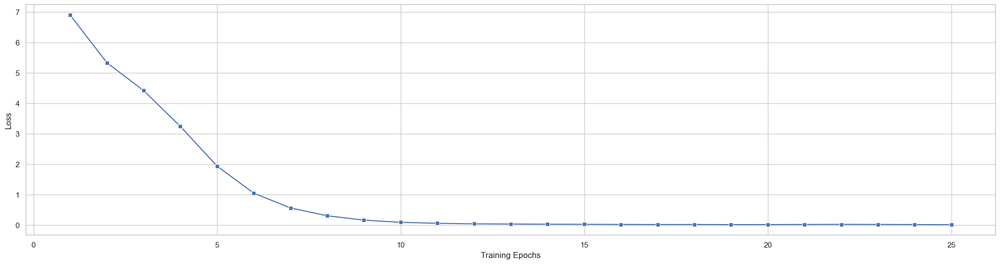

In [349]:
plt.figure(figsize=(25, 6))
sns.lineplot(x=range(1, training_epochs+1), y=losses, marker="s")
plt.xlabel("Training Epochs")
plt.ylabel("Loss");